# 02 — Cleaning, Normalization and Locked Evaluation Splits

## Research objective
Convert only verified source annotations into two reproducible object-detection
datasets. Every retained image must have provenance, valid geometry, an explicit
class mapping and a fixed split. The two diseases remain independent tasks.

## Input and output

| Input | Output |
|---|---|
| Executed notebook 01 and its per-image audit | Compact RGB JPEGs and YOLO labels |
| Reviewed class interpretation and overlays | Group-isolated train/validation/test splits |
| Duplicate constraints and exclusion reasons | CSV manifests, split locks and a data card |

No training or test-set model evaluation occurs in this notebook.

## 1. Load the audited handoff and reviewed mapping

Both sources were inspected in notebook 01. Approval records verify schema interpretation, not clinical diagnoses.

In [1]:
from pathlib import Path
import json
import sys
import platform
import pandas as pd
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "src/configs/sources.json").is_file())
REPORT = ROOT / "docs/reports/data_preparation"
REPORT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 85)
print("Python:", platform.python_version())
print("Project:", ROOT)

from dentalselfie.acquire import digest
from dentalselfie.research import prepare_task, validate_prepared, plot_prepared_grid, write_json

AUDIT_PATH = REPORT / "audit_records.jsonl"
records = pd.read_json(AUDIT_PATH, lines=True)
pairs = pd.read_csv(REPORT / "duplicate_candidates.csv", keep_default_na=False)
mappings = json.loads((ROOT / "src/configs/label_mappings.json").read_text())
assert all(mappings[task]["approved"] for task in ("caries", "gum"))
display(pd.DataFrame([{"task": task, "source_format": item["box_format"],
                       "classes": json.dumps(item["classes"]), "evidence": item["evidence"]}
                      for task, item in mappings.items()]))
print("Audit SHA-256:", digest(AUDIT_PATH))


Python: 3.11.15
Project: C:\Users\huynh\Desktop\oral-disease


,task,source_format,classes,evidence
0,caries,labelme_xyxy_pixels,"{""D"": 0, ""d"": 0}","2026-10-20: actual LabelMe names, VOC cross-check and source overlays reviewed. U..."
1,gum,yolo_cxcywh_normalized,"{""0"": null, ""1"": null, ""2"": 0, ""3"": 1, ""4"": 1, ""5"": 2, ""6"": 2}","2026-10-20: source Table 2 and labeling section, caption checks 00929/00001/00733..."


Audit SHA-256: 6b07eb0ad4a34e06609f2c174cd23973a03fd6c265cc08574f1eead8e8c612f9


## 2. Apply the recorded exclusions

Quarantine whole images with unknown labels, invalid geometry or unsupported
orientation. Keep the audit trail and raw files. Exact duplicate annotation
conflicts remain unresolved source issues, not arbitrary label choices.
Explicitly empty valid annotations may remain as negatives; missing annotations may not.

In [2]:
selected = records[records.eligible].copy()
summary = records.groupby("task").agg(source_images=("sample_id", "size"),
                                       retained_images=("eligible", "sum")).reset_index()
summary["excluded_images"] = summary.source_images - summary.retained_images
display(summary)
display(pd.read_csv(REPORT / "final_exclusion_reasons.csv"))
assert selected.label_path.ne("").all()
assert selected.groupby(["task", "sha256"]).size().max() == 1


,task,source_images,retained_images,excluded_images
0,caries,6265,2175,4090
1,gum,1096,1067,29


,task,reasons,images
0,caries,invalid_box_geometry,14
1,caries,missing_annotation_not_a_negative,4038
2,caries,nonstandard_exif_orientation_requires_review,5
3,caries,unknown_caries_shape_or_class,38
4,gum,exact_duplicate_annotation_conflict,28
5,gum,invalid_box_geometry,1


## 3. Declare preprocessing and split settings before materialization

- Resize only when needed: longest edge at most 1,280 pixels, with aspect ratio preserved.
- Convert stored pixels to RGB JPEG, quality 95, 4:4:4 chroma; strip EXIF metadata.
- Preserve normalized box coordinates under resizing. No color enhancement or augmentation.
- Target 70%/15%/15% by observable groups, seed 42. Group sizes can prevent exact ratios.
- Retain original source split names for provenance; these new splits are not the paper's benchmark.

Compact images reduce later upload and GPU input costs. This is one fixed preprocessing
protocol for both old and new models; it is not a claimed accuracy improvement.

In [3]:
SEED = 42
MAX_EDGE = 1280
JPEG_QUALITY = 95
LOCAL_WORKERS = 4

display(pd.DataFrame([{"seed": SEED, "max_edge": MAX_EDGE, "jpeg_quality": JPEG_QUALITY,
                       "local_workers": LOCAL_WORKERS, "target_split": "70/15/15"}]))


,seed,max_edge,jpeg_quality,local_workers,target_split
0,42,1280,95,4,70/15/15


## 4. Materialize both task datasets

The helper validates source hashes, writes images/labels and creates same-volume hard links for split folders where supported. Locked outputs are reused only under the identical audit/config fingerprint.

In [4]:
from time import perf_counter

started = perf_counter()
manifests = []
for task in ("caries", "gum"):
    print(f"Preparing {task} ...", flush=True)
    manifest = prepare_task(ROOT, task, selected, AUDIT_PATH, seed=SEED,
                            max_edge=MAX_EDGE, quality=JPEG_QUALITY, workers=LOCAL_WORKERS)
    manifests.append(manifest)
prepared = pd.concat(manifests, ignore_index=True)
print(f"Prepared {len(prepared):,} images in {perf_counter() - started:.1f} seconds.")
display(prepared[["task", "split", "sample_id", "width", "height", "label_count"]].head(10))


Preparing caries ...


caries: reusing the identical locked dataset


Preparing gum ...


gum: reusing the identical locked dataset


Prepared 3,242 images in 0.1 seconds.


,task,split,sample_id,width,height,label_count
0,caries,train,001a583208693867e5f1,1280,959,5
1,caries,train,0037f0c99a98b1b14066,1280,719,5
2,caries,test,009c2595b1d2cda8b470,1280,959,1
3,caries,train,00d42cb98e5c1a19ee06,1280,959,5
4,caries,train,00f344df4c7cad48d5ba,1280,959,4
5,caries,val,014f6255c69d00613d65,1280,960,1
6,caries,train,0160e9e52a65d6c7c76b,1280,853,3
7,caries,val,0182cba362328365bb6c,1280,959,5
8,caries,train,01f17661254086e79526,1280,719,2
9,caries,train,0217bfc6fba83cf754cd,1280,719,2


## 5. Inspect split sizes, negative examples and class balance

Class counts are reported, not artificially balanced by duplicating validation/test examples. A no-inflammation gingival box is a local appearance label, not proof of a healthy patient.

In [5]:
split_summary = prepared.groupby(["task", "split"]).agg(
    images=("sample_id", "size"), groups=("group_id", "nunique"),
    boxes=("label_count", "sum"), bytes=("bytes", "sum")).reset_index()
split_summary["image_fraction"] = split_summary.images / split_summary.groupby("task").images.transform("sum")
split_summary["image_mb"] = split_summary.bytes / 1_000_000
split_summary.to_csv(REPORT / "split_summary.csv", index=False)
display(split_summary)
display(prepared.assign(explicit_negative=prepared.label_count.eq(0)).groupby("task").explicit_negative.sum())


,task,split,images,groups,boxes,bytes,image_fraction,image_mb
0,caries,test,326,188,952,105902069,0.149885,105.902069
1,caries,train,1522,887,4651,485447237,0.699770,485.447237
2,caries,val,327,189,1054,105792030,0.150345,105.792030
3,gum,test,160,160,1920,48175498,0.149953,48.175498
4,gum,train,747,747,8969,228080824,0.700094,228.080824
5,gum,val,160,160,1920,49409797,0.149953,49.409797


task
caries    38
gum        0
Name: explicit_negative, dtype: int64

## 6. Verify the complete output, not only samples

For every output, verify image/label hashes, class IDs, normalized box validity and
split materialization. Assert zero cross-split overlap of group IDs, original byte
hashes and prepared image hashes. Every retained visual-candidate pair must stay
in one split. Assert that each declared class appears in every split.

These checks establish observable isolation; unknown repeated patients may still
exist because the sources do not provide independently verifiable patient identifiers.

In [6]:
class_counts = validate_prepared(ROOT, prepared, pairs)
class_counts.to_csv(REPORT / "class_distribution.csv", index=False)
display(class_counts)

from dentalselfie.data import assign_splits
for task in ("caries", "gum"):
    expected = assign_splits(selected[selected.task == task].sort_values("sample_id").to_dict("records"), SEED)
    expected_by_id = {row["sample_id"]: row["split"] for row in expected}
    actual_by_id = prepared[prepared.task == task].set_index("sample_id").split.to_dict()
    assert expected_by_id == actual_by_id
print("All output-integrity, observed-overlap, class-coverage and seed-reproducibility checks passed.")


,task,split,class_id,class_name,boxes,validation,same_split_visual_pairs_checked
0,caries,train,0,visible_caries,4651,passed,12
1,caries,val,0,visible_caries,1054,passed,12
2,caries,test,0,visible_caries,952,passed,12
3,gum,train,0,no_visible_inflammation,210,passed,0
4,gum,train,1,mild_inflammation,3829,passed,0
5,gum,train,2,marked_inflammation,4930,passed,0
6,gum,val,0,no_visible_inflammation,49,passed,0
7,gum,val,1,mild_inflammation,932,passed,0
8,gum,val,2,marked_inflammation,939,passed,0
9,gum,test,0,no_visible_inflammation,43,passed,0


All output-integrity, observed-overlap, class-coverage and seed-reproducibility checks passed.


## 7. Visualize the prepared labels and balance

These plots show the actual resized outputs. The class IDs correspond to the target mapping, not the original source IDs.

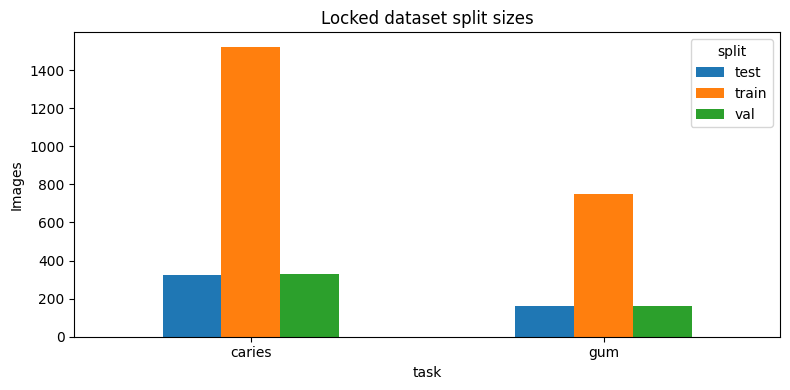

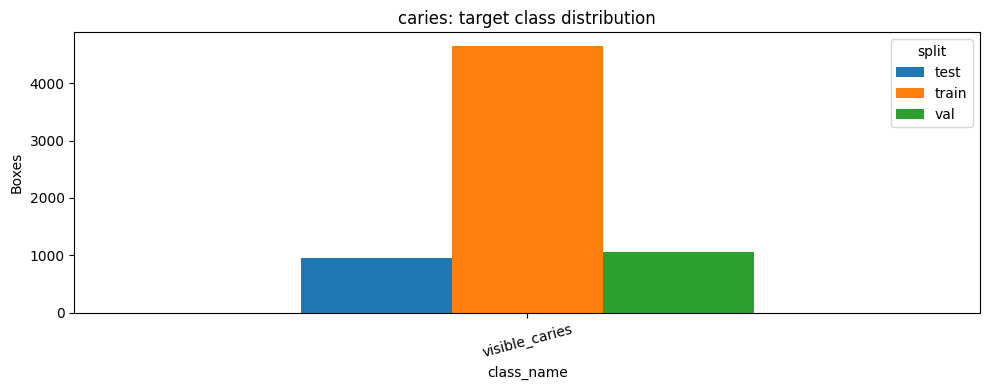

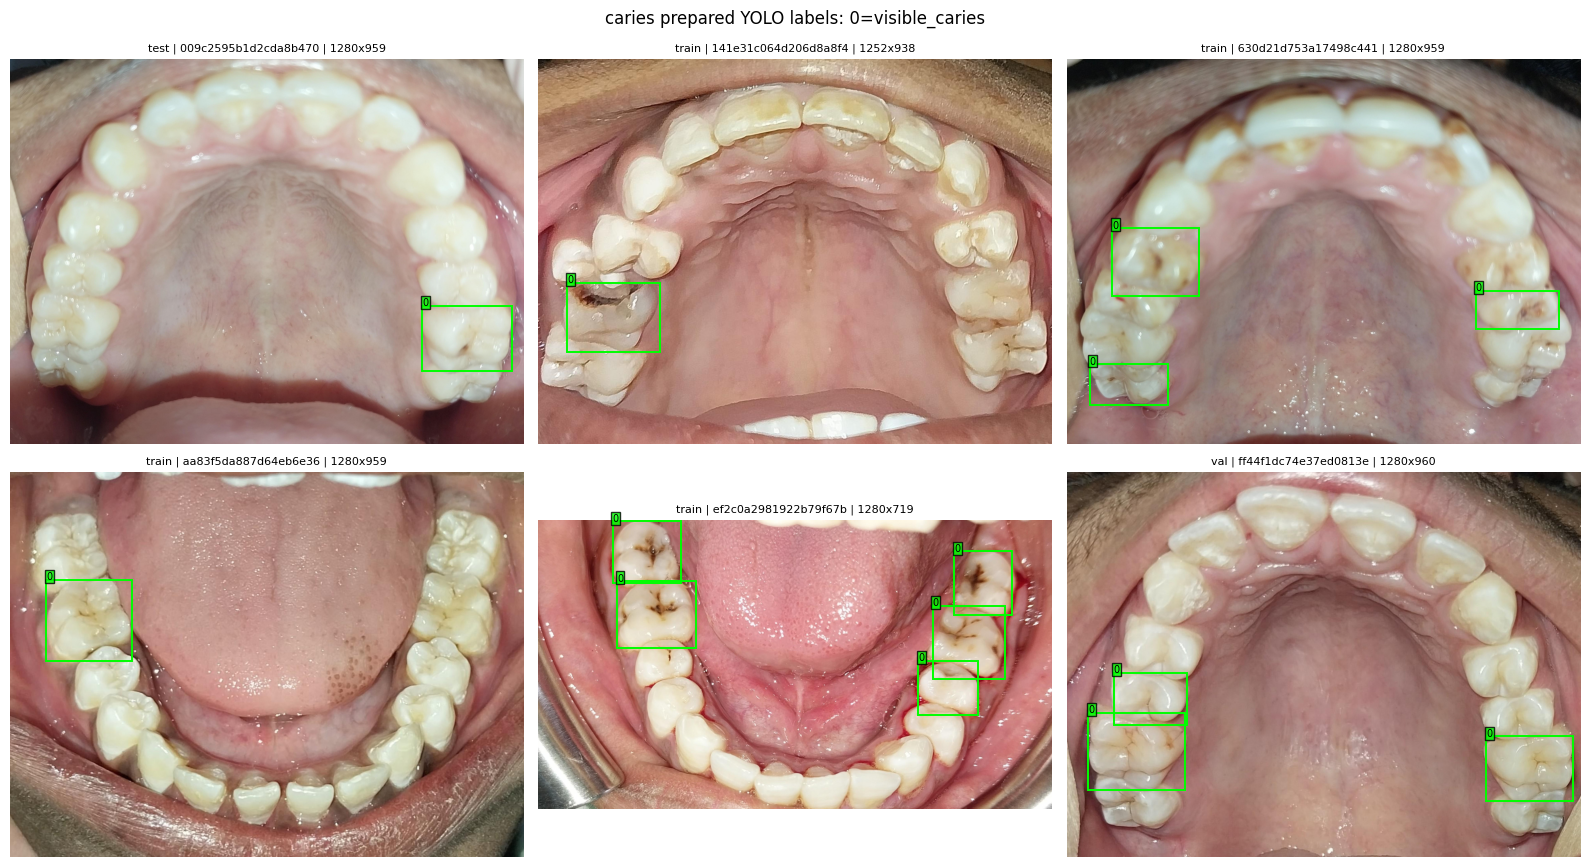

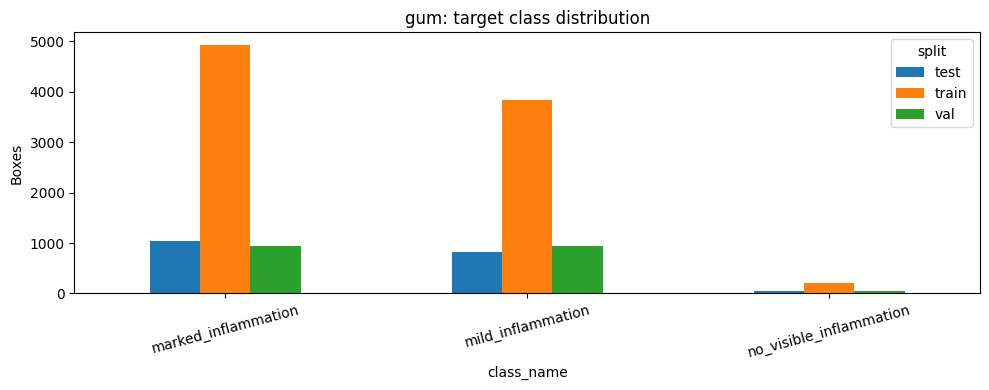

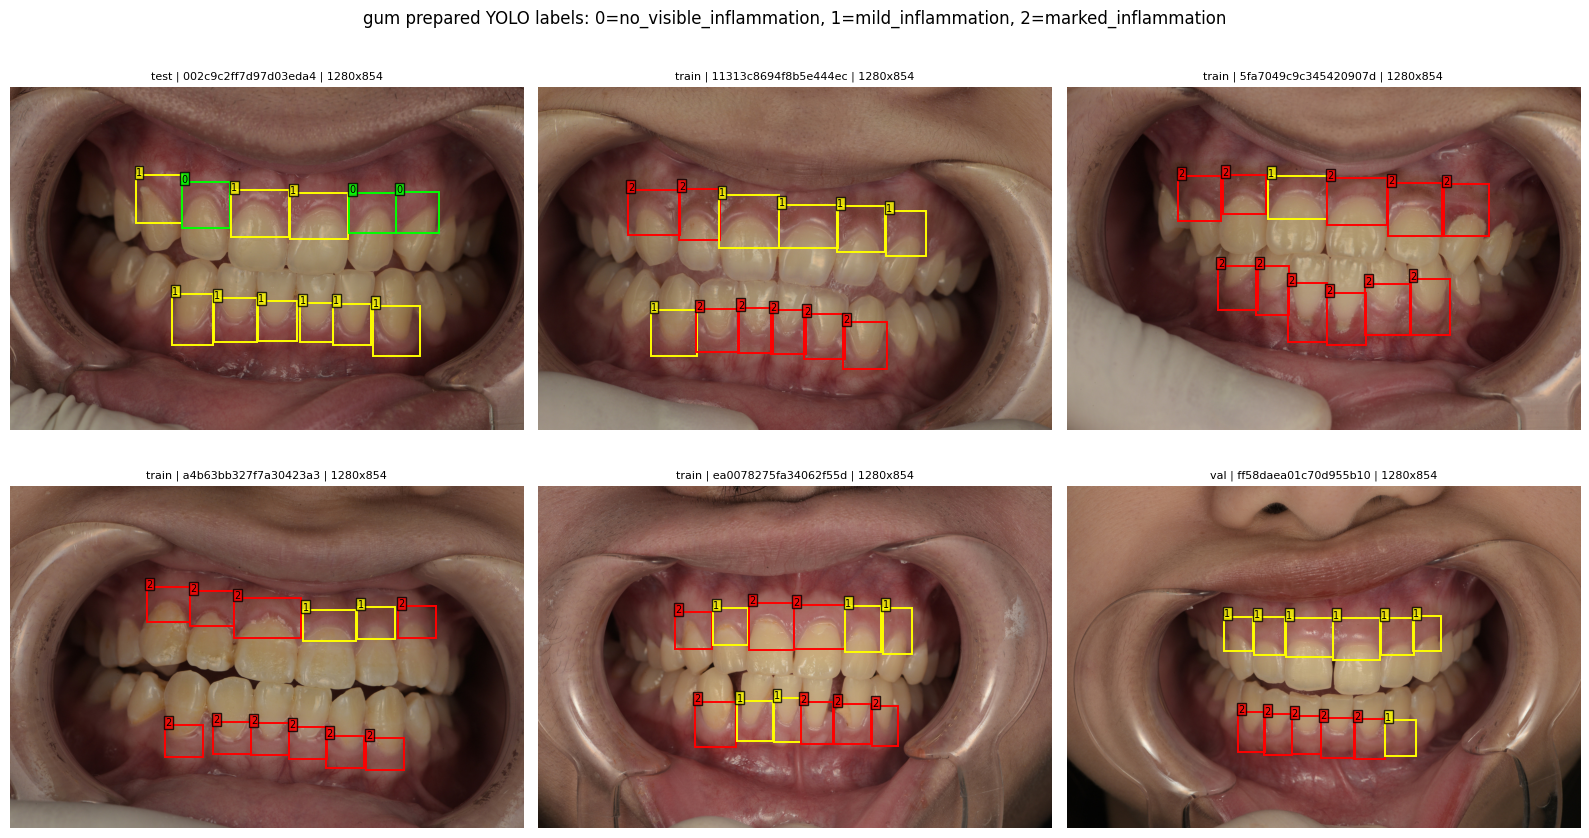

In [7]:
import matplotlib.pyplot as plt

split_summary.pivot(index="task", columns="split", values="images").plot.bar(
    figsize=(8, 4), ylabel="Images", title="Locked dataset split sizes", rot=0)
plt.tight_layout()
plt.savefig(REPORT / "split_sizes.png", dpi=140)
plt.show()

for task in ("caries", "gum"):
    table = class_counts[class_counts.task == task].pivot(index="class_name", columns="split", values="boxes")
    table.plot.bar(figsize=(10, 4), ylabel="Boxes", title=f"{task}: target class distribution", rot=15)
    plt.tight_layout()
    plt.savefig(REPORT / f"{task}_class_balance.png", dpi=140)
    plt.show()
    plot_prepared_grid(ROOT, prepared, REPORT / f"{task}_prepared_overlays.png", task)
    plt.show()


## 8. Record storage reduction, provenance and split locks

Resize/re-encoding changes image bytes, so manifests store both source and prepared SHA-256 fingerprints. Split-lock files bind the source audit, mapping and output CSV.

In [8]:
source_bytes = selected.groupby("task").bytes.sum().rename("source_eligible_bytes")
output_bytes = prepared.groupby("task").bytes.sum().rename("prepared_image_bytes")
storage = pd.concat([source_bytes, output_bytes], axis=1).reset_index()
storage["reduction_factor"] = storage.source_eligible_bytes / storage.prepared_image_bytes
storage.to_csv(REPORT / "storage_summary.csv", index=False)
display(storage)

lock_rows = []
for task in ("caries", "gum"):
    path = ROOT / "data/manifests" / f"{task}.lock.json"
    lock = json.loads(path.read_text())
    lock_rows.append({"task": task, "split_sha256": lock["splits_sha256"],
                      "lock_sha256": digest(path), "dataset_yaml": f"data/processed/{task}/dataset/data.yaml"})
locks = pd.DataFrame(lock_rows)
display(locks)
locks.to_csv(REPORT / "dataset_fingerprints.csv", index=False)


,task,source_eligible_bytes,prepared_image_bytes,reduction_factor
0,caries,511802681,697141336,0.734145
1,gum,6385288908,325666119,19.606857


,task,split_sha256,lock_sha256,dataset_yaml
0,caries,6e446143aa483e5af2937fdfde197204098911a602187b29428462b6344d0665,28505e2b6d41051be26a479a0839d659ca8d0d3fc189b747500b368c2328c775,data/processed/caries/dataset/data.yaml
1,gum,17951a893d64d81ad5d8318abac5fb004c791cc3b411d07adaa387cb1ca39bd3,65eafe331e6a325976aea04a844f0b37564dc0c524ba2daa36879e11604a8b4d,data/processed/gum/dataset/data.yaml


## 9. Publish the data card and executed conclusion

Prepared datasets are local outputs. Training, GPU benchmarking and Kaggle uploads belong to the next stage.

In [9]:
from importlib.metadata import version
from IPython.display import Markdown

environment = {name: version(name) for name in
               ("Pillow", "numpy", "pandas", "matplotlib", "ImageHash", "nbclient", "rarfile")}
write_json(REPORT / "preparation_environment.json", environment)

lines = ["# DentalSelfie Data Card — Prepared Dataset v1", "",
         "## Provenance", "",
         "- Caries: https://doi.org/10.5281/zenodo.14827784 (Dataset.zip; publisher MD5 verified).",
         "- Gingivitis: https://doi.org/10.17632/3253gj88rr.1 (original RAR; local SHA-256 recorded).",
         "- Sources declare CC BY 4.0. Retain attribution when sharing derived data.", "",
         "## Measured retained dataset", "",
         "| Task | Source images | Retained | Excluded |", "|---|---:|---:|---:|"]
for row in summary.to_dict("records"):
    lines.append(f"| {row['task']} | {row['source_images']} | {row['retained_images']} | {row['excluded_images']} |")
lines += ["", "## Split images", "", "| Task | Split | Images | Groups | Boxes |", "|---|---|---:|---:|---:|"]
for row in split_summary.to_dict("records"):
    lines.append(f"| {row['task']} | {row['split']} | {row['images']} | {row['groups']} | {row['boxes']} |")
lines += ["", "## Transformations", "",
          "Named caries rectangles map D/d to visible_caries. Gingivitis source 0/1 jaw ROIs are excluded; "
          "2 maps to no_visible_inflammation, 3/4 to mild_inflammation, 5/6 to marked_inflammation.", "",
          "Stored pixel orientation is retained for source EXIF 0/1 after dimension/overlay checks. "
          "Defined non-identity rotations, unknown source classes/shapes and invalid boxes are quarantined. "
          "Images become RGB JPEG quality 95, 4:4:4, longest edge at most 1280; no upsampling or augmentation.", "",
          "New approximately 70/15/15 grouped splits use seed 42. These differ from published source splits. "
          "Original paths, source split names, raw/prepared hashes and class evidence remain traceable.", "",
          "## Limitations", "",
          "Missing caries annotations are not negative labels. Unknown M/m classes are not interpreted. "
          "Conflicting exact-duplicate gingivitis annotations are excluded in their entirety. "
          "Observable grouping uses filename case tokens, byte hashes and conservative visual similarity. "
          "Patient-disjointness is not independently certified; residual undetected repeated patients remain possible.", "",
          "Sources contain supported clinical photography, not a validated phone-selfie population. "
          "Class mappings reflect local visible appearance and are not a full clinical diagnosis. "
          "A separate real-phone study is needed later. Test data must not be used for model selection.", "",
          "## Reproduction", "",
          "Run notebooks/01_data_audit.ipynb then notebooks/02_prepare_splits.ipynb in the pinned local environment. "
          "See data/manifests/*.lock.json and docs/reports/data_preparation/ for exact fingerprints and exclusions."]
card_path = REPORT / "DATA_CARD.md"
card_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
display(Markdown(card_path.read_text()))

print(f"COMPLETED: {len(prepared):,} local prepared images across two tasks; all integrity checks passed.")
print("No model training or Kaggle upload was performed.")


# DentalSelfie Data Card â€” Prepared Dataset v1

## Provenance

- Caries: https://doi.org/10.5281/zenodo.14827784 (Dataset.zip; publisher MD5 verified).
- Gingivitis: https://doi.org/10.17632/3253gj88rr.1 (original RAR; local SHA-256 recorded).
- Sources declare CC BY 4.0. Retain attribution when sharing derived data.

## Measured retained dataset

| Task | Source images | Retained | Excluded |
|---|---:|---:|---:|
| caries | 6265 | 2175 | 4090 |
| gum | 1096 | 1067 | 29 |

## Split images

| Task | Split | Images | Groups | Boxes |
|---|---|---:|---:|---:|
| caries | test | 326 | 188 | 952 |
| caries | train | 1522 | 887 | 4651 |
| caries | val | 327 | 189 | 1054 |
| gum | test | 160 | 160 | 1920 |
| gum | train | 747 | 747 | 8969 |
| gum | val | 160 | 160 | 1920 |

## Transformations

Named caries rectangles map D/d to visible_caries. Gingivitis source 0/1 jaw ROIs are excluded; 2 maps to no_visible_inflammation, 3/4 to mild_inflammation, 5/6 to marked_inflammation.

Stored pixel orientation is retained for source EXIF 0/1 after dimension/overlay checks. Defined non-identity rotations, unknown source classes/shapes and invalid boxes are quarantined. Images become RGB JPEG quality 95, 4:4:4, longest edge at most 1280; no upsampling or augmentation.

New approximately 70/15/15 grouped splits use seed 42. These differ from published source splits. Original paths, source split names, raw/prepared hashes and class evidence remain traceable.

## Limitations

Missing caries annotations are not negative labels. Unknown M/m classes are not interpreted. Conflicting exact-duplicate gingivitis annotations are excluded in their entirety. Observable grouping uses filename case tokens, byte hashes and conservative visual similarity. Patient-disjointness is not independently certified; residual undetected repeated patients remain possible.

Sources contain supported clinical photography, not a validated phone-selfie population. Class mappings reflect local visible appearance and are not a full clinical diagnosis. A separate real-phone study is needed later. Test data must not be used for model selection.

## Reproduction

Run notebooks/01_data_audit.ipynb then notebooks/02_prepare_splits.ipynb in the pinned local environment. See data/manifests/*.lock.json and docs/reports/data_preparation/ for exact fingerprints and exclusions.


COMPLETED: 3,242 local prepared images across two tasks; all integrity checks passed.
No model training or Kaggle upload was performed.


## Implementation appendix — readable processing code

The following cell displays the exact shared implementation used above, with syntax
highlighting. Its saved output makes the processing code readable inside this notebook.
The shared module remains the single implementation so fixes do not diverge between notebooks.

In [10]:
import inspect
from IPython.display import Code
from dentalselfie import research

for function_name in ('prepare_task', 'validate_prepared'):
    print(function_name)
    display(Code(inspect.getsource(getattr(research, function_name)), language='python'))


prepare_task


def prepare_task(root: Path, task: str, selected: pd.DataFrame, audit_path: Path,
                 seed: int = 42, max_edge: int = 1280, quality: int = 95, workers: int = 4) -> pd.DataFrame:
    """Create compact RGB JPEGs and valid YOLO labels, then lock observable groups.

    Prepared split files are hard links on the same volume where supported, avoiding
    a second full image copy. Original files are never modified or moved.
    """
    from PIL import Image
    import PIL
    from .data import assign_splits

    if task not in ("caries", "gum"):
        raise ValueError("Unknown dataset task")
    root = root.resolve()
    manifest_dir = root / "data/manifests"
    manifest_dir.mkdir(parents=True, exist_ok=True)
    mapping_path = root / "src/configs/label_mappings.json"
    mapping = json.loads(mapping_path.read_text())[task]
    if not mapping["approved"]:
        raise ValueError(f"{task}: source interpretation has not been verified")
    settings = {"protocol": "dentalselfie-data-v1", "task": task, "seed": seed,
                "max_edge": max_edge, "jpeg_quality": quality, "jpeg_subsampling": 0,
                "pillow": PIL.__version__, "audit_sha256": digest(audit_path),
                "mapping_sha256": digest(mapping_path)}
    lock_path = manifest_dir / f"{task}.lock.json"
    split_path = manifest_dir / f"{task}.splits.csv"
    destination = root / "data/processed" / task
    if lock_path.is_file():
        lock = json.loads(lock_path.read_text())
        if lock["settings"] != settings or lock["splits_sha256"] != digest(split_path):
            raise ValueError("Locked dataset differs from this request; create a new protocol version explicitly")
        print(f"{task}: reusing the identical locked dataset", flush=True)
        return pd.read_csv(split_path, keep_default_na=False)
    stage = destination if destination.exists() else root / ".venv/work/data_preparation" / task
    if destination.exists() and not (destination / "preparation_settings.json").is_file():
        raise FileExistsError(f"Unrecognized prepared destination without a lock: {destination}")
    stage.mkdir(parents=True, exist_ok=True)
    stage_settings = stage / "preparation_settings.json"
    if stage_settings.is_file() and json.loads(stage_settings.read_text()) != settings:
        raise ValueError("Partial staging belongs to another preparation protocol")
    write_json(stage_settings, settings)
    selected = selected[selected.task == task].sort_values("sample_id")
    if len(selected) == 0:
        raise ValueError(f"{task}: no eligible images")
    assignment = assign_splits(selected.to_dict("records"), seed=seed)

    def normalize(row):
        source = root / row["image_path"]
        if digest(source) != row["sha256"]:
            raise ValueError(f"Source image changed after audit: {source}")
        image_out = stage / "images" / f"{row['sample_id']}.jpg"
        label_out = stage / "labels" / f"{row['sample_id']}.txt"
        image_out.parent.mkdir(parents=True, exist_ok=True)
        label_out.parent.mkdir(parents=True, exist_ok=True)
        text = serialize_boxes(row["target_boxes"])
        reuse = False
        if image_out.is_file() and label_out.is_file() and label_out.read_text() == text:
            try:
                with Image.open(image_out) as image:
                    image.load()
                    width, height = image.size
                    reuse = image.format == "JPEG" and image.mode == "RGB" and max(width, height) <= max_edge
            except OSError:
                reuse = False
        if not reuse:
            with Image.open(source) as image:
                image = image.convert("RGB")
                image.thumbnail((max_edge, max_edge), Image.Resampling.LANCZOS)
                width, height = image.size
                image.save(image_out, format="JPEG", quality=quality, subsampling=0, optimize=False)
        label_out.write_bytes(text.encode("utf-8"))
        prepared = {"sample_id": ro

validate_prepared


def validate_prepared(root: Path, manifests: pd.DataFrame, pairs: pd.DataFrame) -> pd.DataFrame:
    """Check bytes, geometry, class coverage and cross-split group/duplicate isolation."""
    from .data import parse_yolo
    import yaml

    rows = []
    for task, task_rows in manifests.groupby("task"):
        lock_path = root / "data/manifests" / f"{task}.lock.json"
        lock = json.loads(lock_path.read_text())
        split_path = root / "data/manifests" / f"{task}.splits.csv"
        assert digest(split_path) == lock["splits_sha256"]
        dataset = root / "data/processed" / task / "dataset"
        names = yaml.safe_load((dataset / "data.yaml").read_text())["names"]
        class_counts = Counter()
        for row in task_rows.to_dict("records"):
            assert digest(root / row["image"]) == row["sha256"]
            assert digest(root / row["label"]) == row["label_sha256"]
            assert digest(dataset / "images" / row["split"] / f"{row['sample_id']}.jpg") == row["sha256"]
            assert digest(dataset / "labels" / row["split"] / f"{row['sample_id']}.txt") == row["label_sha256"]
            boxes = parse_yolo((root / row["label"]).read_text())
            assert len(boxes) == row["label_count"]
            for class_id, *coordinates in boxes:
                assert 0 <= class_id < len(names)
                class_counts[(row["split"], class_id)] += 1
        for key in ("group_id", "source_sha256", "sha256"):
            assert task_rows.groupby(key).split.nunique().max() == 1, f"Cross-split overlap: {task}/{key}"
        lookup = task_rows.set_index("sample_id").split.to_dict()
        checked_pairs = 0
        for pair in pairs[pairs.task == task].to_dict("records"):
            if pair["sample_a"] in lookup and pair["sample_b"] in lookup:
                assert lookup[pair["sample_a"]] == lookup[pair["sample_b"]]
                checked_pairs += 1
        for split in ("train", "val", "test"):
            assert len(task_rows[task_rows.split == split]) > 0
            for class_id, name in enumerate(names):
                assert class_counts[(split, class_id)] > 0, f"Class absent from split: {task}/{split}/{name}"
                rows.append({"task": task, "split": split, "class_id": class_id, "class_name": name,
                             "boxes": class_counts[(split, class_id)], "validation": "passed",
                             "same_split_visual_pairs_checked": checked_pairs})
    return pd.DataFrame(rows)